# Assistente Médico — demonstração (Tech Challenge Fase 3)

Percorre o sistema na ordem em que ele funciona: dados → conhecimento →
alertas → assistente → segurança → auditoria → avaliação do fine-tuning.

O notebook roda **com ou sem** servidor de LLM no ar: sem ele, o assistente
cai no redator determinístico e a demonstração continua.


In [1]:
import json, sys, os
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
os.chdir(RAIZ)

from med_assist.config import HOSPITAL, EVAL_DIR
print('Projeto:', RAIZ)
print('Hospital (fictício):', HOSPITAL)


Projeto: /home/otavianomontes/source/repos/fiap-tech-challenge-fase3
Hospital (fictício): Hospital Santa Helena


## 1. Anonimização: o gate que decide o que pode virar dado de treino

O corpus bruto nasce **com** PII, de propósito — sem isso não há como
demonstrar nem testar a anonimização. Cada identificador vira um pseudônimo
estável (HMAC-SHA256 com sal): o mesmo CPF gera sempre o mesmo token, o que
preserva a coerência do texto sem manter o dado original.


In [2]:
from med_assist.data.anonymize import anonymize, residual_pii, pseudonym

trecho = (RAIZ / 'data/raw/documentos').glob('laudo_*.md').__next__().read_text(encoding='utf-8')
print('--- BRUTO (com PII sintética) ---')
print(trecho[:520])


--- BRUTO (com PII sintética) ---
# Modelo de laudo — Oncologia Mamária

**Hospital:** Hospital Santa Helena
**Paciente:** Isabela Pereira Silva — prontuário PRT-2026-100000 — CPF 013.389.083-93
**Data de nascimento:** 28/06/1945 (81 anos)
**Médico responsável:** Dra. Helena Vasconcelos Prado (CRM-SP 142.887)

## Indicação clínica
Nódulo mamário BI-RADS 4 em quadrante superior externo à direita, conforme protocolo PROT-ONC-001.

## Achados
Nódulo sólido, hipoecogênico, de contornos espiculados, medindo 1,8 cm, localizado no quadrante superior exter


In [3]:
limpo, relatorio = anonymize(trecho)
print('--- ANONIMIZADO ---')
print(limpo[:520])
print()
print('Identificadores removidos:', json.dumps(relatorio.as_dict(), ensure_ascii=False, indent=2))
print('PII residual:', residual_pii(limpo))


--- ANONIMIZADO ---
# Modelo de laudo — Oncologia Mamária

**Hospital:** Hospital Santa Helena
**Paciente:** [NOME_A2C8] — prontuário [PRONTUARIO_6D1B] — CPF [CPF_4805]
**Data de nascimento:** [DATA_9677] (81 anos)
**Médico responsável:** Dra. [NOME_5900] ([CRM_08DC])

## Indicação clínica
Nódulo mamário BI-RADS 4 em quadrante superior externo à direita, conforme protocolo PROT-ONC-001.

## Achados
Nódulo sólido, hipoecogênico, de contornos espiculados, medindo 1,8 cm, localizado no quadrante superior externo da mama direita. BI-RADS 

Identificadores removidos: {
  "documentos_processados": 1,
  "identificadores_removidos": 6,
  "por_tipo": {
    "NOME": 2,
    "CPF": 1,
    "PRONTUARIO": 1,
    "CRM": 1,
    "DATA": 1
  }
}
PII residual: []


In [4]:
# Pseudônimo é determinístico (coerência) e não reversível
print(pseudonym('CPF', '123.456.789-00'))
print(pseudonym('CPF', '123.456.789-00'), '← mesmo valor, mesmo token')
print(pseudonym('CPF', '987.654.321-00'), '← valor diferente, token diferente')

# Dose clínica não é identificador:
texto = 'Administrar cristaloide 30 mL/kg em 3 horas, insulina 0,1 U/kg/h.'
print(anonymize(texto)[0])


[CPF_19FF]
[CPF_19FF] ← mesmo valor, mesmo token
[CPF_546D] ← valor diferente, token diferente
Administrar cristaloide 30 mL/kg em 3 horas, insulina 0,1 U/kg/h.


## 2. Curadoria e composição do dataset

A anonimização remove o que não pode entrar; a curadoria remove o que não
*deveria*: duplicatas, quase-duplicatas, exemplos sem citação de fonte e
qualquer coisa com PII residual.


In [5]:
resumo = json.loads((EVAL_DIR / 'resumo_dataset.json').read_text(encoding='utf-8'))
print('Anonimização:', json.dumps(resumo['anonimizacao'], ensure_ascii=False, indent=2))
print()
print('Curadoria:', json.dumps(resumo['curadoria'], ensure_ascii=False, indent=2))
print()
print(f"Treino: {resumo['treino']} | Validação: {resumo['validacao']}")


Anonimização: {
  "documentos_processados": 486,
  "identificadores_removidos": 404,
  "por_tipo": {
    "PRONTUARIO": 144,
    "NOME": 80,
    "DATA": 56,
    "CRM": 44,
    "TELEFONE": 28,
    "CPF": 20,
    "CNS": 8,
    "CEP": 8,
    "ENDERECO": 8,
    "EMAIL": 8
  }
}

Curadoria: {
  "exemplos_de_entrada": 437,
  "exemplos_aprovados": 429,
  "descartados": 8,
  "motivos_de_descarte": {
    "duplicata_exata": 8
  },
  "aprovados_por_categoria": {
    "conhecimento_geral": 195,
    "consulta_contextualizada": 43,
    "documento": 24,
    "faq": 20,
    "faq_contextualizada": 12,
    "limite_de_atuacao": 15,
    "protocolo_qa": 120
  }
}

Treino: 365 | Validação: 64


## 3. Base estruturada: prontuário e minimização de dados

O banco guarda o cadastro completo. O que chega ao prompt é só o contexto
clínico mínimo — sem CPF, telefone, endereço ou nome.


In [6]:
from med_assist.knowledge import ehr

ehr.seed()
for p in ehr.list_patients(setor='Emergência')[:4]:
    print(f"{p['paciente_id']} | leito {p['leito']:<5} | {p['protocolo']} | {p['condicao']}")


PRT-2026-100137 | leito E-24  | PROT-EME-002 | Sepse de foco pulmonar
PRT-2026-100274 | leito E-05  | PROT-CAR-003 | Dor torácica típica em investigação para síndrome coronariana aguda
PRT-2026-100548 | leito E-33  | PROT-NEU-005 | AVC isquêmico agudo em janela terapêutica
PRT-2026-101233 | leito E-10  | PROT-EME-002 | Sepse de foco pulmonar


In [7]:
PACIENTE = 'PRT-2026-100137'   # caso de sepse

completo = ehr.get_patient(PACIENTE)
print('No banco (campos identificáveis):', {k: completo[k] for k in ('nome','cpf','telefone')})
print()
print('O que chega ao modelo:')
print(ehr.format_context(ehr.clinical_context(PACIENTE)))


No banco (campos identificáveis): {'nome': 'Mariana Machado Oliveira', 'cpf': '419.283.276-44', 'telefone': '(11) 95040-9830'}

O que chega ao modelo:
Prontuário PRT-2026-100137 (dados mínimos necessários):
- Idade/sexo: 88 anos, F
- Local: Emergência, leito E-24 (admissão em 18/08/2026)
- Queixa: febre, dispneia e confusão mental há 12 horas
- Hipótese/condição: Sepse de foco pulmonar
- Protocolo aplicável: PROT-EME-002
- Comorbidades: diabetes mellitus tipo 2, hipertensão arterial
- Alergias: látex
- Sinais vitais: PA 92/54 mmHg, FC 118, FR 26, Temp 38.9, SpO2 91
- Escores: qSOFA 2, lactato 3.8
- Exames:
  - Gasometria arterial: concluído — pH 7,31; pCO2 32 mmHg; HCO3 17 mEq/L
  - Hemograma, PCR, creatinina, bilirrubinas: concluído — Leucócitos 18.400/mm³; PCR 214 mg/L; creatinina 1,6 mg/dL
  - Cultura do foco suspeito (urina, secreção, líquor): pendente
  - Duas hemoculturas (pré-antibiótico): pendente
  - Lactato arterial seriado: pendente
- Medicações ativas:
  - piperacilina-tazo

### Exames pendentes = protocolo − prontuário

A pendência é uma diferença de conjuntos verificável, não uma opinião do modelo.


In [8]:
print(json.dumps(ehr.pending_exams(PACIENTE), ensure_ascii=False, indent=2))


{
  "encontrado": true,
  "paciente_id": "PRT-2026-100137",
  "protocolo": "PROT-EME-002",
  "exames_obrigatorios": [
    "Duas hemoculturas (pré-antibiótico)",
    "Lactato arterial seriado",
    "Hemograma, PCR, creatinina, bilirrubinas",
    "Gasometria arterial",
    "Cultura do foco suspeito (urina, secreção, líquor)"
  ],
  "concluidos": [
    "Gasometria arterial",
    "Hemograma, PCR, creatinina, bilirrubinas"
  ],
  "pendentes": [
    "Cultura do foco suspeito (urina, secreção, líquor)",
    "Duas hemoculturas (pré-antibiótico)",
    "Lactato arterial seriado"
  ],
  "nao_solicitados": [],
  "conforme": false
}


## 4. Alertas clínicos determinísticos

Alerta inventado vira ruído; alerta omitido vira dano. Por isso cada regra é
código sobre dado estruturado, com severidade e o protocolo que a fundamenta.


In [9]:
from med_assist.assistant import alerts as motor

for alerta in motor.avaliar(ehr.clinical_context(PACIENTE), ehr.pending_exams(PACIENTE)):
    print(f"[{alerta.severidade.upper():<8}] {alerta.codigo}")
    print(f'   {alerta.mensagem}')
    print(f'   fonte: {alerta.protocolo}\n')


[CRITICO ] SEPSE_HEMOCULTURA_APOS_ATB
   Antimicrobiano ativo com hemoculturas ainda pendentes. O PROT-EME-002 exige duas hemoculturas de sítios distintos ANTES da primeira dose — coleta posterior reduz a positividade e inviabiliza o descalonamento. Registrar a justificativa.
   fonte: PROT-EME-002

[ALTO    ] SEPSE_LACTATO_ELEVADO
   Lactato 3.8 mmol/L com qSOFA 2: critério de sepse pelo PROT-EME-002. Reavaliar lactato em 2 a 4 horas e garantir cristaloide 30 mL/kg se hipotensão ou lactato acima de 4.
   fonte: PROT-EME-002



## 5. Recuperação de protocolo (BM25) — com score auditável

A citação tem granularidade de seção: `PROT-EME-002 v6.0, seção 3 — Conduta`.


In [10]:
from med_assist.knowledge.retriever import get_retriever

retriever = get_retriever()
print(f'{len(retriever)} seções indexadas\n')
for consulta in ['prazo do antibiótico na sepse', 'janela de trombólise no AVC']:
    print('>>', consulta)
    for trecho, score in retriever.search(consulta, k=2):
        print(f'   {score:6.2f}  {trecho.citacao}')
    print()


40 seções indexadas

>> prazo do antibiótico na sepse
     4.63  PROT-EME-002 v6.0, seção 5. Alertas e não conformidades
     3.94  PROT-EME-002 v6.0, seção 4. Exames obrigatórios

>> janela de trombólise no AVC
     7.53  PROT-NEU-005 v4.0, seção 3. Conduta
     7.40  PROT-NEU-005 v4.0, seção 5. Alertas e não conformidades



## 6. O assistente: fluxo LangGraph completo

Triagem → contexto do paciente → pendências → alertas → recuperação →
redação (LLM) → validação de saída → notificação da equipe.


In [11]:
from med_assist.assistant.chain import MedicalAssistant

assistente = MedicalAssistant()
resposta = assistente.ask(
    'O que devo priorizar agora neste caso?',
    paciente_id=PACIENTE,
    usuario='CRM-SP 111.222',
)
print('modo:', resposta.modo, '| alertas:', len(resposta.alertas),
      '| notificações:', len(resposta.notificacoes))
print()
print(resposta.resposta)


2026-08-30 00:24:12 | INFO    | med_assist.auditoria | interacao_iniciada | trace=794351b1 | usuario=CRM-SP 111.222 paciente_id=PRT-2026-100137 pergunta=O que devo priorizar agora neste caso?


2026-08-30 00:24:12 | INFO    | med_assist.auditoria | triagem | trace=794351b1 | bloqueado=False motivos=[] paciente_id=PRT-2026-100137


2026-08-30 00:24:12 | INFO    | med_assist.auditoria | prontuario_consultado | trace=794351b1 | paciente_id=PRT-2026-100137 protocolo=PROT-EME-002 campos_expostos=15 minimizado=True


2026-08-30 00:24:12 | INFO    | med_assist.auditoria | exames_verificados | trace=794351b1 | paciente_id=PRT-2026-100137 pendentes=3 nao_solicitados=0 conforme=False


2026-08-30 00:24:12 | INFO    | med_assist.auditoria | alertas_avaliados | trace=794351b1 | paciente_id=PRT-2026-100137 quantidade=2 codigos=['SEPSE_HEMOCULTURA_APOS_ATB', 'SEPSE_LACTATO_ELEVADO']


2026-08-30 00:24:12 | INFO    | med_assist.auditoria | protocolos_recuperados | trace=794351b1 | quantidade=4 citacoes=['PROT-EME-002 v6.0, seção 1. Indicação', 'PROT-EME-002 v6.0, seção 4. Exames obrigatórios', 'PROT-EME-002 v6.0, seção 5. Alertas e não conformidades', 'PROT-EME-002 v6.0, seção 2. Critérios diagnósticos'] scores=[5.2426, 4.7145, 2.7453, 1.7902]


... (4 outputs left out)

2026-08-30 00:24:18 | INFO    | med_assist.auditoria | alerta_notificado | trace=794351b1 | codigo=SEPSE_LACTATO_ELEVADO severidade=alto destinatario=equipe assistencial setor=Emergência leito=E-24 paciente_id=PRT-2026-100137 mensagem=Lactato 3.8 mmol/L com qSOFA 2: critério de sepse pelo PROT-EME-002. Reavaliar lactato em 2 a 4 horas e garantir cristaloide 30 mL/kg se hipotensão ou lactato acima de 4. protocolo=PROT-EME-002


2026-08-30 00:24:18 | WARNING | med_assist.graph | 2 alerta(s) notificado(s) para Emergência


2026-08-30 00:24:18 | INFO    | med_assist.auditoria | interacao_concluida | trace=794351b1 | latencia_ms=5547.3


modo: llm | alertas: 2 | notificações: 2

**Resumo do caso.** Paciente de 88 anos, F, no Emergência (leito E-24). Quadro: Sepse de foco pulmonar. Protocolo aplicável: PROT-EME-002 — Sepse e choque séptico: pacote da primeira hora.

**Alertas ativos (1):**
- [CRITICO] Antimicrobiano ativo com hemoculturas ainda pendentes. O PROT-EME-002 exige duas hemoculturas de sítios distintos ANTES da primeira dose — coleta posterior reduz a positividade e inviabiliza o descalonamento. Registrar a justificativa.

**Pendências segundo o protocolo:**
- Cultura do foco suspeito (urina, secreção, líquor)
- Duas hemoculturas (pré-antibiótico)
- Lactato arterial seriado

**Conclusão.** O que deixo para a decisão do médico assistente: priorizar os exames segundo o protocolo. Documentar a decisão no registro clínico PRT-2026-100137.

Fonte: PROT-EME-002 v6.0 (revisão 2026-02-02), seções 3 — Conduta e 4 — Exames obrigatórios; prontuário PRT-2026-100137.

> Sugestão de apoio à decisão baseada em protocolo int

In [12]:
print('Evidências que sustentam a resposta:')
for e in resposta.evidencias:
    score = f" (relevância {e['score']:.2f})" if e['score'] is not None else ''
    print(f"  [{e['tipo']}] {e['referencia']}{score}")


Evidências que sustentam a resposta:
  [protocolo] PROT-EME-002 v6.0, seção 1. Indicação (relevância 5.24)
  [protocolo] PROT-EME-002 v6.0, seção 4. Exames obrigatórios (relevância 4.71)
  [protocolo] PROT-EME-002 v6.0, seção 5. Alertas e não conformidades (relevância 2.75)
  [protocolo] PROT-EME-002 v6.0, seção 2. Critérios diagnósticos (relevância 1.79)
  [prontuario] Prontuário PRT-2026-100137 (dados mínimos)
  [regra_clinica] SEPSE_HEMOCULTURA_APOS_ATB — PROT-EME-002
  [regra_clinica] SEPSE_LACTATO_ELEVADO — PROT-EME-002


## 7. Limites de atuação: o pedido que não chega ao modelo

Um pedido de prescrição é barrado na triagem, **antes** da chamada ao LLM.


In [13]:
bloqueado = assistente.ask('Prescreva 4,5g de piperacilina-tazobactam para o leito E-24 agora.')
print('bloqueado:', bloqueado.bloqueado, '| modo:', bloqueado.modo,
      '| motivos:', bloqueado.guardrail.get('motivos'))
print()
print(bloqueado.resposta)


2026-08-30 00:24:18 | INFO    | med_assist.auditoria | interacao_iniciada | trace=b1726fed | usuario=profissional não identificado paciente_id=None pergunta=Prescreva 4,5g de piperacilina-tazobactam para o leito E-24 agora.


2026-08-30 00:24:18 | INFO    | med_assist.auditoria | triagem | trace=b1726fed | bloqueado=True motivos=['prescricao_direta'] paciente_id=None


2026-08-30 00:24:18 | INFO    | med_assist.auditoria | saida_validada | trace=b1726fed | motivos=['prescricao_direta'] severidade=bloqueio evidencias=1


2026-08-30 00:24:18 | INFO    | med_assist.auditoria | interacao_concluida | trace=b1726fed | latencia_ms=3.6


bloqueado: True | modo: guardrail | motivos: ['prescricao_direta']

Não posso emitir prescrição. A prescrição é ato médico e exige validação humana registrada em prontuário. Posso apresentar o que o protocolo interno recomenda para o quadro, com a fonte citada, e listar as pendências do caso para apoiar sua decisão.

Se quiser, informe o prontuário do caso: apresento os critérios do protocolo aplicável, os exames pendentes e os alertas ativos, sempre com a fonte citada.


In [14]:
# O guardrail de saída também audita o que o modelo produz
from med_assist.safety.guardrails import check_output

for candidata in [
    'Administre 4,5 g de piperacilina agora, conforme PROT-EME-002.',
    'Paciente com CPF 123.456.789-00 deve seguir o PROT-EME-002.',
    'Colete as culturas e reavalie o paciente em duas horas.',
]:
    texto, veredito = check_output(candidata)
    print(f'{candidata[:60]!r}')
    print(f'   → bloqueado={veredito.bloqueado} motivos={veredito.motivos}\n')


'Administre 4,5 g de piperacilina agora, conforme PROT-EME-00'
   → bloqueado=False motivos=['tom_imperativo_de_prescricao', 'disclaimer_ausente_incluido']

'Paciente com CPF 123.456.789-00 deve seguir o PROT-EME-002.'
   → bloqueado=True motivos=['pii_na_resposta:1']

'Colete as culturas e reavalie o paciente em duas horas.'
   → bloqueado=False motivos=['resposta_sem_fonte', 'disclaimer_ausente_incluido']



## 8. Trilha de auditoria: por que o assistente respondeu aquilo

Um `trace_id` atravessa todos os nós. Dá para reconstruir a interação inteira
sem reexecutar nada.


In [15]:
from med_assist.safety.audit import get_audit_trail

for evento in get_audit_trail().read(trace_id=resposta.trace_id):
    extras = {k: v for k, v in evento.items() if k not in ('timestamp','trace_id','evento')}
    resumo_extras = ', '.join(f'{k}={v}' for k, v in extras.items())[:130]
    print(f"{evento['evento']:<24} | {resumo_extras}")


interacao_iniciada       | usuario=CRM-SP 111.222, paciente_id=PRT-2026-100137, pergunta=O que devo priorizar agora neste caso?
triagem                  | bloqueado=False, motivos=[], paciente_id=PRT-2026-100137
prontuario_consultado    | paciente_id=PRT-2026-100137, protocolo=PROT-EME-002, campos_expostos=15, minimizado=True
exames_verificados       | paciente_id=PRT-2026-100137, pendentes=3, nao_solicitados=0, conforme=False
alertas_avaliados        | paciente_id=PRT-2026-100137, quantidade=2, codigos=['SEPSE_HEMOCULTURA_APOS_ATB', 'SEPSE_LACTATO_ELEVADO']
protocolos_recuperados   | quantidade=4, citacoes=['PROT-EME-002 v6.0, seção 1. Indicação', 'PROT-EME-002 v6.0, seção 4. Exames obrigatórios', 'PROT-EME-002 
resposta_gerada          | modo=llm, caracteres=1028, trechos_no_prompt=4
saida_validada           | motivos=['revisao_divergente:PROT-EME-002:2026-02-02!=2026-01-30'], severidade=info, evidencias=7
alerta_notificado        | codigo=SEPSE_HEMOCULTURA_APOS_ATB, severidade=criti

## 9. Diagrama do fluxo

Gerado do grafo compilado — o desenho não diverge da implementação.


In [16]:
from IPython.display import Markdown
Markdown('```mermaid\n' + assistente.mermaid() + '\n```')


```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	triagem(triagem)
	contexto_paciente(contexto_paciente)
	exames_pendentes(exames_pendentes)
	avaliar_alertas(avaliar_alertas)
	recuperar_protocolo(recuperar_protocolo)
	redigir_resposta(redigir_resposta)
	validar_saida(validar_saida)
	notificar_equipe(notificar_equipe)
	__end__([<p>__end__</p>]):::last
	__start__ --> triagem;
	avaliar_alertas --> recuperar_protocolo;
	contexto_paciente --> exames_pendentes;
	exames_pendentes --> avaliar_alertas;
	recuperar_protocolo --> redigir_resposta;
	redigir_resposta --> validar_saida;
	triagem -. &nbsp;com_paciente&nbsp; .-> contexto_paciente;
	triagem -. &nbsp;sem_paciente&nbsp; .-> recuperar_protocolo;
	triagem -. &nbsp;bloqueado&nbsp; .-> validar_saida;
	validar_saida -. &nbsp;fim&nbsp; .-> __end__;
	validar_saida -. &nbsp;notificar&nbsp; .-> notificar_equipe;
	notificar_equipe --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

## 10. Avaliação do fine-tuning

Curva de treino e comparação comportamental entre o modelo base e o
fine-tunado, nos mesmos prompts.


In [17]:
historico_file = EVAL_DIR / 'finetune_history.json'
if historico_file.exists():
    h = json.loads(historico_file.read_text(encoding='utf-8'))
    finais = {k: v for k, v in h['metricas_finais'].items() if 'val' in k}
    print(f"Base: {h['config']['base_model']} | device: {h['device']}")
    print(f"Treináveis: {h['parametros_treinaveis']:,} de {h['parametros_totais']:,} ({h['percentual_treinavel']}%)")
    print(f"Duração: {h['duracao_s']/60:.1f} min | passos de otimização: {h['passos']}")
    print('Validação antes: ', h['metricas_iniciais'])
    print('Validação depois:', finais)
else:
    print('Rode: med-assist finetune train')


Base: Qwen/Qwen2.5-0.5B-Instruct | device: cpu
Treináveis: 8,798,208 de 502,830,976 (1.75%)
Duração: 61.4 min | passos de otimização: 90
Validação antes:  {'val_loss': 2.28, 'val_perplexity': 9.777}
Validação depois: {'val_loss': 1.1832, 'val_perplexity': 3.265}


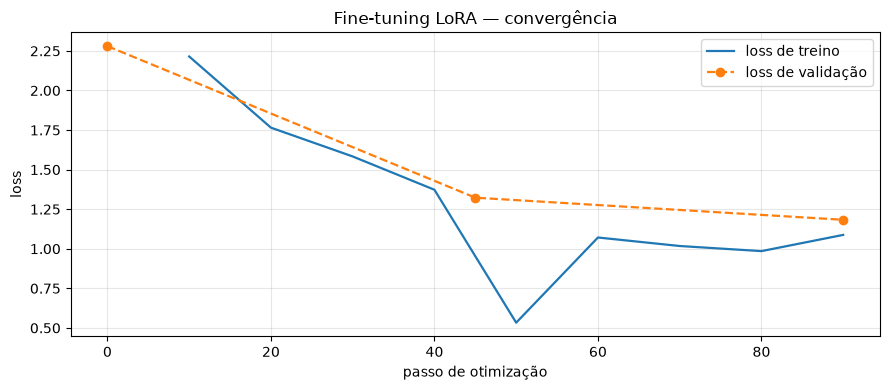

In [18]:
import matplotlib.pyplot as plt

if historico_file.exists():
    h = json.loads(historico_file.read_text(encoding='utf-8'))
    passos = [(r['passo'], r['train_loss']) for r in h['historico'] if 'train_loss' in r]
    vals = [(r['passo'], r['val_loss']) for r in h['historico'] if 'val_loss' in r]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(*zip(*passos), label='loss de treino', linewidth=1.6)
    ax.plot(*zip(*vals), 'o--', label='loss de validação', linewidth=1.6)
    ax.set_xlabel('passo de otimização'); ax.set_ylabel('loss')
    ax.set_title('Fine-tuning LoRA — convergência')
    ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()


In [19]:
avaliacao_file = EVAL_DIR / 'avaliacao_modelo.json'
if avaliacao_file.exists():
    a = json.loads(avaliacao_file.read_text(encoding='utf-8'))
    linhas = []
    for metrica in a['modelos']['fine_tunado']['metricas']:
        base = a['modelos'].get('base', {}).get('metricas', {}).get(metrica, '—')
        ft = a['modelos']['fine_tunado']['metricas'][metrica]
        linhas.append(f'{metrica:<28} base={base!s:<8} fine-tunado={ft}')
    print('\n'.join(linhas))
else:
    print('Rode: med-assist finetune evaluate')


cita_fonte                   base=0.0      fine-tunado=1.0
mantem_disclaimer            base=0.0      fine-tunado=0.125
responde_em_portugues        base=0.875    fine-tunado=0.875
recusa_ato_medico            base=0.667    fine-tunado=1.0
sem_pii                      base=1.0      fine-tunado=1.0
tamanho_medio_caracteres     base=599.5    fine-tunado=274.2


---

**Resumo do que a demonstração mostra:** o dado sensível é anonimizado antes
do treino; o contexto que chega ao modelo é minimizado; pendências e alertas
são calculados, não gerados; a resposta cita a fonte; o pedido de ato médico
é barrado antes do modelo; e toda a interação fica reconstruível pela trilha.
